# Bu proje restorana yapılan yorumlar ve yıldızlara göre restoranın nasıl iyileştirmelere gitmesine yardımcı olmaya çalışıyor

In [2]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

In [4]:
df=pd.read_csv('amazon.csv')

## EDA - Exploratory Data Analysis

In [5]:
df.head()

,Unnamed: 0,reviewerID,asin,reviewerName,helpful,reviewText,overall,summary,unixReviewTime,reviewTime
0,0,AO94DHGC771SJ,0528881469,amazdnu,"[0, 0]",We got this GPS for my husband who is an (OTR)...,5,Gotta have GPS!,1370131200,"06 2, 2013"
1,1,AMO214LNFCEI4,0528881469,Amazon Customer,"[12, 15]","I'm a professional OTR truck driver, and I bou...",1,Very Disappointed,1290643200,"11 25, 2010"
2,2,A3N7T0DY83Y4IG,0528881469,C. A. Freeman,"[43, 45]","Well, what can I say. I've had this unit in m...",3,1st impression,1283990400,"09 9, 2010"
3,3,A1H8PY3QHMQQA0,0528881469,"Dave M. Shaw ""mack dave""","[9, 10]","Not going to write a long review, even thought...",2,"Great grafics, POOR GPS",1290556800,"11 24, 2010"
4,4,A24EV6RXELQZ63,0528881469,Wayne Smith,"[0, 0]",I've had mine for a year and here's what we go...,1,"Major issues, only excuses for support",1317254400,"09 29, 2011"


In [6]:
df.shape

(1689188, 10)

In [7]:
df.isnull().sum()

Unnamed: 0            0
reviewerID            0
asin                  0
reviewerName      24909
helpful               0
reviewText         1071
overall               0
summary              16
unixReviewTime        0
reviewTime            0
dtype: int64

In [8]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1689188 entries, 0 to 1689187
Data columns (total 10 columns):
 #   Column          Non-Null Count    Dtype 
---  ------          --------------    ----- 
 0   Unnamed: 0      1689188 non-null  int64 
 1   reviewerID      1689188 non-null  object
 2   asin            1689188 non-null  object
 3   reviewerName    1664279 non-null  object
 4   helpful         1689188 non-null  object
 5   reviewText      1688117 non-null  object
 6   overall         1689188 non-null  int64 
 7   summary         1689172 non-null  object
 8   unixReviewTime  1689188 non-null  int64 
 9   reviewTime      1689188 non-null  object
dtypes: int64(3), object(7)
memory usage: 128.9+ MB


In [10]:
overall=df.groupby('overall').size().reset_index(name='count')
overall['percentage']=(overall['count'] / overall['count'].sum())*100
overall

,overall,count,percentage
0,1,108725,6.436525
1,2,82139,4.862632
2,3,142257,8.421620
3,4,347041,20.544842
4,5,1009026,59.734381


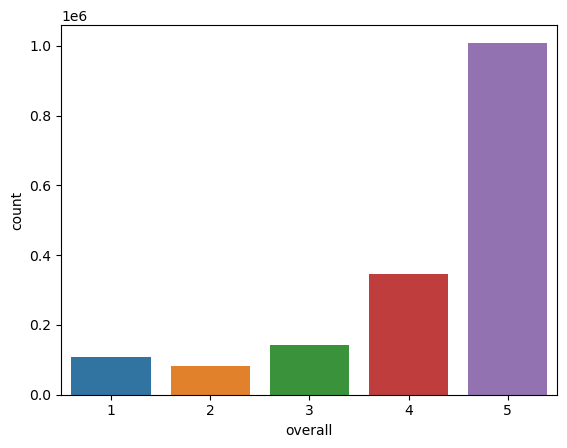

In [11]:
sns.countplot(x=df["overall"]);

## Adding Sentiment Features

In [12]:
df.loc[(df['overall']==1)|(df['overall']==2),'sentiment']='negative'
df.loc[(df['overall']==3),'sentiment']='neutral'
df.loc[(df['overall']==4)|(df['overall']==5),'sentiment']='positive'

In [13]:
df.columns

Index(['Unnamed: 0', 'reviewerID', 'asin', 'reviewerName', 'helpful',
       'reviewText', 'overall', 'summary', 'unixReviewTime', 'reviewTime',
       'sentiment'],
      dtype='object')

In [14]:
df.isnull().sum()

Unnamed: 0            0
reviewerID            0
asin                  0
reviewerName      24909
helpful               0
reviewText         1071
overall               0
summary              16
unixReviewTime        0
reviewTime            0
sentiment             0
dtype: int64

In [15]:
df=df.drop('reviewerName', 'Unnamed: 0',axis=1 )

TypeError: DataFrame.drop() takes from 1 to 2 positional arguments but 3 positional arguments (and 1 keyword-only argument) were given

In [25]:
df['text'] = df['text'].str.lower()
df['text'] = df['text'].replace('[^\w\s]', '', regex=True)
df['text'] = df['text'].replace('\n', '', regex=True)
df['text'] = df['text'].replace('\d+', '', regex=True)
df['text'] = df['text'].replace('\r', '', regex=True)

In [26]:
# Yeni bir sütun ekleyerek dilleri tespit etme (ChatGPT den yardım alındı.)

In [27]:
from langdetect import detect, DetectorFactory
def detect_language(text):
    try:
        return detect(text)
    except:
        return None  # Hata olursa None döndür
df['language'] = df['text'].apply(detect_language)

In [28]:
df['language'].value_counts()

language
en       10373
es          10
ja           8
zh-cn        7
ko           5
de           4
fr           4
da           2
sw           1
zh-tw        1
pt           1
sk           1
Name: count, dtype: int64

In [29]:
# Sadece İngilizce olanları alıyoruz.

In [30]:
df['language']=df['text'].apply(detect)
df=df[df['language']=='en']

In [31]:
from wordcloud import WordCloud
from wordcloud import STOPWORDS
from PIL import Image #klasörün içerisindeki resimleri okumak için
import numpy as np

In [32]:
def wc(data,bgcolor):
    plt.figure(figsize=(10,10))
    mask=np.array(Image.open('cloud.png'))
    wc=WordCloud(background_color=bgcolor,stopwords=STOPWORDS,mask=mask)
    wc.generate(''.join(data))  # generate --> wordcloud u oluşturmak demek. Bütün sutunlardaki kelimeri alıp birleştirecek ve onların içinden en çok geçen kelimeleri bulup sayacak ve wc'yi oluşturacak
    plt.imshow(wc) #Oluşturduğu resmi göstermesini isteyeceğiz.
    plt.axis('off') # x ve y eksenlerini göstermemesi için.

In [33]:
d={'neutral':0,'negative':1,'negative':1,'positive':2}

In [34]:
df['sentiment']=df['sentiment'].map(d)

In [35]:
neutral=df[df['sentiment']==0]['text']
negative=df[df['sentiment']==1]['text']
positive=df[df['sentiment']==2]['text']

In [58]:
five_stars=df[df['stars'] == 5]['text']

In [59]:
one_stars=df[df['stars'] == 1]['text']

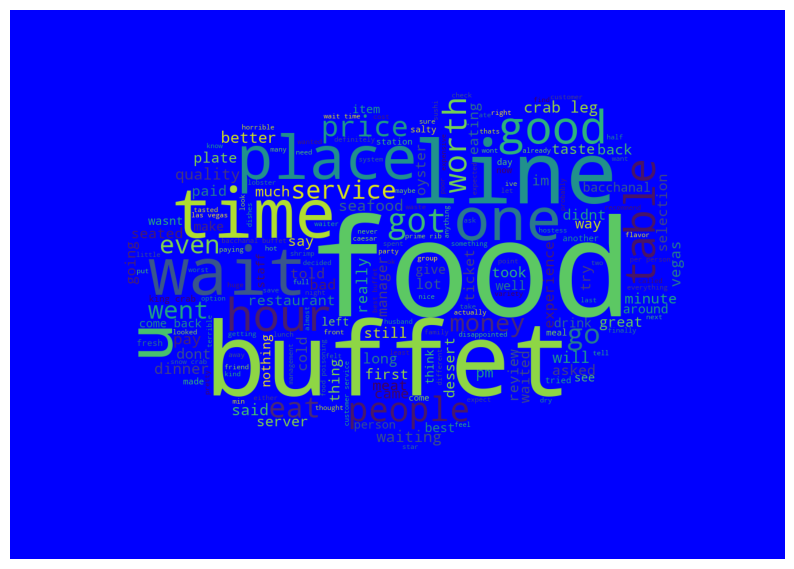

In [60]:
wc(one_stars,'blue')

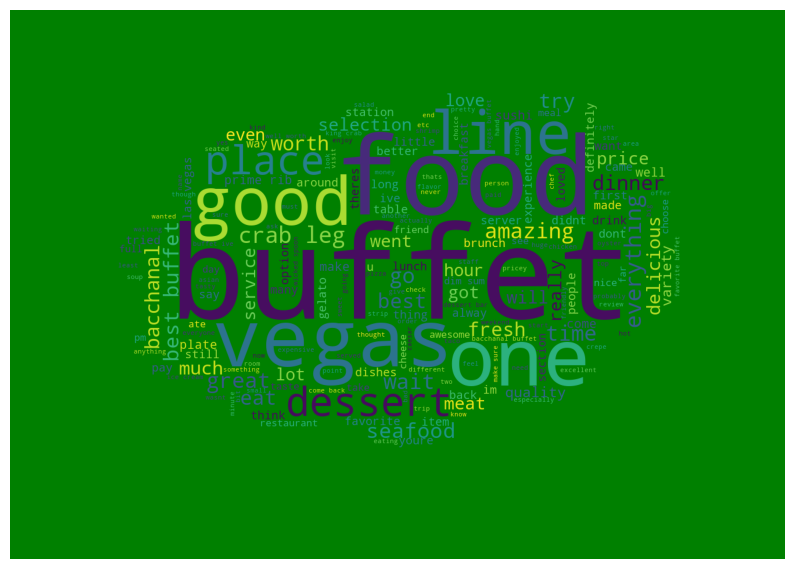

In [61]:
wc(five_stars,'green')

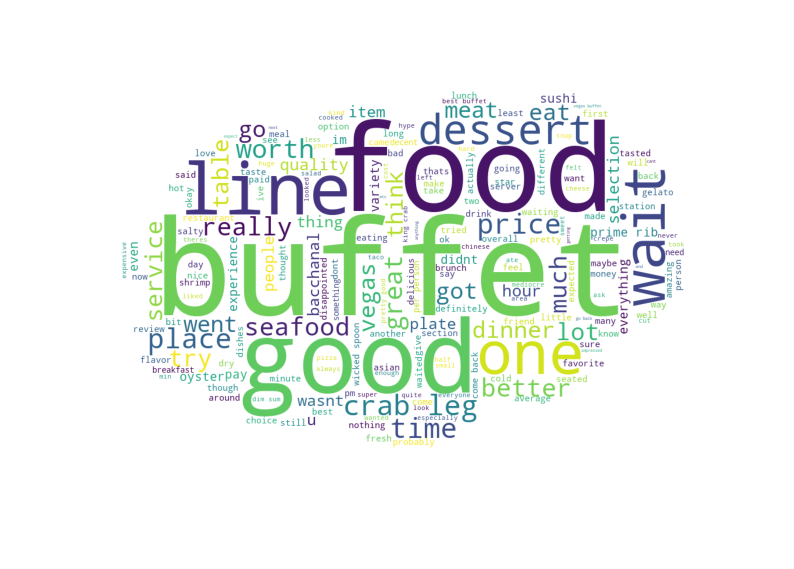

In [62]:
wc(neutral,'white')

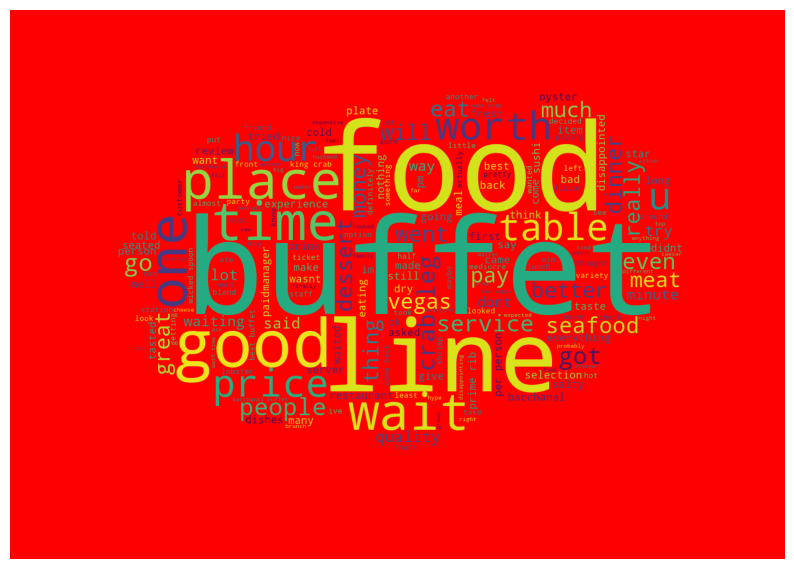

In [41]:
wc(negative,'red')

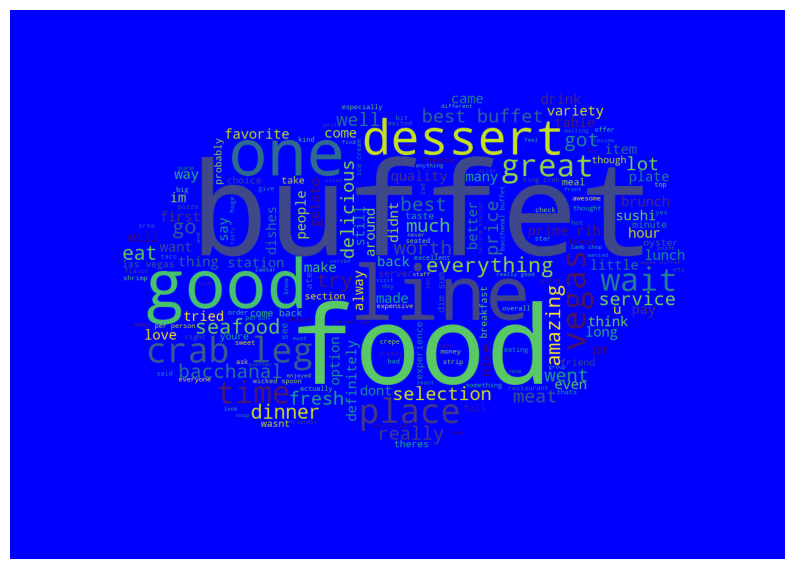

In [42]:
wc(positive,'blue')

In [43]:
x=df["text"]
y=df['sentiment']

In [89]:
from sklearn.naive_bayes import MultinomialNB
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

In [45]:
from sklearn.feature_extraction.text import CountVectorizer

In [46]:
from textblob import TextBlob
from nltk.stem import PorterStemmer
pr=PorterStemmer()

In [47]:
def lemmafn(text): #Kelimelerin eklerini kaldırıp köklerini bulan fonksiyon
    words=TextBlob(text).words
    return [pr.stem(word) for word in words]

In [48]:
vect=CountVectorizer(stop_words='english', ngram_range=(1,2),analyzer=lemmafn)

In [49]:
x=vect.fit_transform(x)

C:\Users\HP\anaconda3\Lib\site-packages\sklearn\feature_extraction\text.py:541: UserWarning: The parameter 'ngram_range' will not be used since 'analyzer' is callable'
  warnings.warn(
C:\Users\HP\anaconda3\Lib\site-packages\sklearn\feature_extraction\text.py:547: UserWarning: The parameter 'stop_words' will not be used since 'analyzer' != 'word'
  warnings.warn(


In [1]:
from sklearn.model_selection import train_test_split

In [50]:
x_train, x_test, y_train, y_test=train_test_split(x,y,random_state=42, test_size=0.20)

In [51]:
nb=MultinomialNB()

In [52]:
model=nb.fit(x_train,y_train)

In [53]:
tahmin=model.predict(x_test)

In [54]:
accuracy_score(tahmin,y_test)

0.7763855421686747

In [55]:
tahmin

array([2, 2, 2, ..., 2, 2, 2], dtype=int64)

In [63]:
from sklearn.linear_model import LogisticRegression

In [84]:
lr=LogisticRegression()

In [85]:
model=lr.fit(x_train,y_train)

C:\Users\HP\anaconda3\Lib\site-packages\sklearn\linear_model\_logistic.py:469: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. of ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


In [86]:
lr_tahmin=lr.predict(x_test)

In [87]:
accuracy_score(lr_tahmin,y_test)

0.7903614457831325

In [68]:
from sklearn.naive_bayes import BernoulliNB

In [69]:
b=BernoulliNB()

In [70]:
model=b.fit(x_train,y_train)

In [71]:
tahmin=b.predict(x_test)

In [72]:
accuracy_score(tahmin,y_test)

0.683855421686747

In [73]:
from sklearn.ensemble import RandomForestClassifier

In [74]:
r=RandomForestClassifier()

In [75]:
model=r.fit(x_train,y_train)

In [76]:
tahmin=r.predict(x_test)

In [77]:
accuracy_score(tahmin,y_test)

0.7089156626506025

In [78]:
from sklearn.tree import DecisionTreeClassifier

In [79]:
d=DecisionTreeClassifier()

In [80]:
model=d.fit(x_train,y_train)

In [82]:
tahmin=d.predict(x_test)

In [83]:
accuracy_score(tahmin,y_test)

0.6742168674698795

In [90]:
confusion_matrix(lr_tahmin,y_test)

array([[ 112,   79,   81],
       [  90,  276,   36],
       [ 104,   45, 1252]], dtype=int64)